# Phase 4.3 — Inference engine benchmarking (vLLM vs SGLang)

Loads `docs/debug/phase4_inference_benchmark_summary.json` from the HumanEval-TS
prompt serving sweep on the B300 box (`gpu_memory_utilization=0.9`, `max_length=512`,
159 prompts, concurrency sweep 1/4/16/32).


In [1]:
import json
from pathlib import Path

DEBUG = Path("../docs/debug")
summary = json.loads((DEBUG / "phase4_inference_benchmark_summary.json").read_text())
rows = summary["rows"]
meta = summary.get("meta", {})
meta

{'vllm_version': '0.32.0',
 'sglang_version': '0.5.22',
 'gpu': 'NVIDIA B300 SXM6 PC',
 'prompt_stats_path': '/root/bonsai/docs/debug/phase4_inference_benchmark_humaneval_ts_prompt_stats.json'}

In [2]:
REP_CONCURRENCY = 16

def pick(engine: str, candidate: str, concurrency: int = REP_CONCURRENCY):
    for r in rows:
        if (
            r["engine"] == engine
            and r["candidate"] == candidate
            and r["concurrency"] == concurrency
        ):
            return r
    raise KeyError((engine, candidate, concurrency))

CANDIDATES = [
    "baseline",
    "depth0_experts64",
    "depth16_experts0",
    "depth0_experts8",
]

table = []
for slug in CANDIDATES:
    for engine in ("vllm", "sglang"):
        r = pick(engine, slug)
        table.append(
            {
                "candidate": slug,
                "params_b": r["params_b"] / 1e9,
                "engine": engine,
                "throughput_tok_s": r["throughput_tok_s"],
                "e2e_p50_ms": r["e2e_latency_ms_p50"],
            }
        )
table[:4]

[{'candidate': 'baseline',
  'params_b': 30.5,
  'engine': 'vllm',
  'throughput_tok_s': 2145.444332871439,
  'e2e_p50_ms': 519.118232999972},
 {'candidate': 'baseline',
  'params_b': 30.5,
  'engine': 'sglang',
  'throughput_tok_s': 2689.9590198812984,
  'e2e_p50_ms': 2970.1447450006526},
 {'candidate': 'depth0_experts64',
  'params_b': 16.03,
  'engine': 'vllm',
  'throughput_tok_s': 2669.5569715110146,
  'e2e_p50_ms': 1235.1959040006477},
 {'candidate': 'depth0_experts64',
  'params_b': 16.03,
  'engine': 'sglang',
  'throughput_tok_s': 3253.6305860488633,
  'e2e_p50_ms': 2497.6405249999516}]

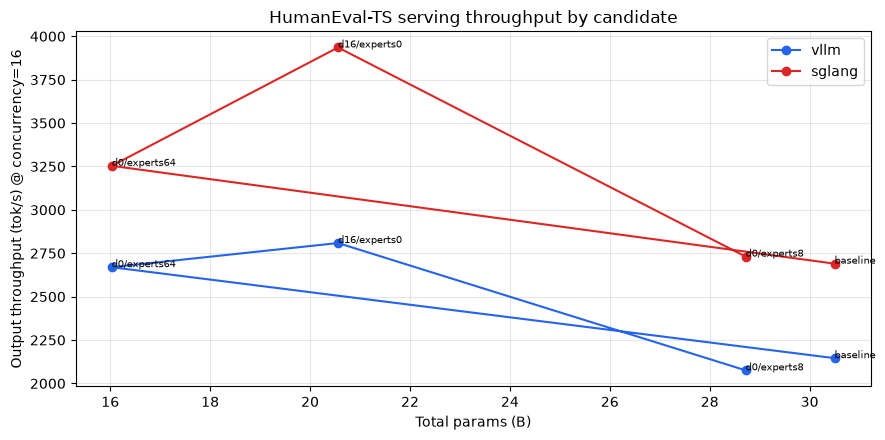

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4.5))
for engine, color in ("vllm", "#2563eb"), ("sglang", "#dc2626"):
    xs = []
    ys = []
    labels = []
    for slug in CANDIDATES:
        r = pick(engine, slug)
        xs.append(r["params_b"] / 1e9)
        ys.append(r["throughput_tok_s"])
        labels.append(slug)
    ax.plot(xs, ys, "o-", label=engine, color=color)
    for x, y, lab in zip(xs, ys, labels, strict=True):
        ax.annotate(lab.replace("depth0_", "d0/").replace("depth16_", "d16/"), (x, y), fontsize=7)
ax.set_xlabel("Total params (B)")
ax.set_ylabel(f"Output throughput (tok/s) @ concurrency={REP_CONCURRENCY}")
ax.set_title("HumanEval-TS serving throughput by candidate")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

vllm depth0_experts64 vs depth16_experts0 tok/s 2669.5569715110146 2808.7658276953534 e2e p50 ms 1235.1959040006477 305.1147349997336
sglang depth0_experts64 vs depth16_experts0 tok/s 3253.6305860488633 3935.4818275223643 e2e p50 ms 2497.6405249999516 2055.606046000321


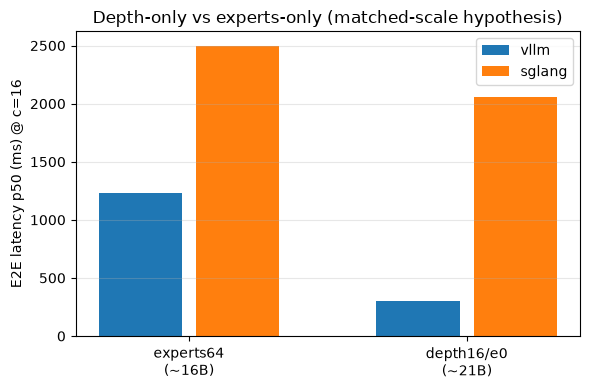

In [4]:
# Hypothesis test: depth-only vs experts-only at ~matched param count
pairs = [
    ("depth0_experts64", "depth16_experts0"),
]
for engine in ("vllm", "sglang"):
    a, b = pairs[0]
    ra, rb = pick(engine, a), pick(engine, b)
    print(
        engine,
        f"{a} vs {b}",
        "tok/s",
        ra["throughput_tok_s"],
        rb["throughput_tok_s"],
        "e2e p50 ms",
        ra["e2e_latency_ms_p50"],
        rb["e2e_latency_ms_p50"],
    )

fig, ax = plt.subplots(figsize=(6, 4))
labels = ["experts64\n(~16B)", "depth16/e0\n(~21B)"]
for i, engine in enumerate(("vllm", "sglang")):
    ra = pick(engine, "depth0_experts64")
    rb = pick(engine, "depth16_experts0")
    vals = [ra["e2e_latency_ms_p50"], rb["e2e_latency_ms_p50"]]
    x = [j + i * 0.35 for j in range(2)]
    ax.bar(x, vals, width=0.3, label=engine)
ax.set_xticks([0.175, 1.175])
ax.set_xticklabels(labels)
ax.set_ylabel(f"E2E latency p50 (ms) @ c={REP_CONCURRENCY}")
ax.set_title("Depth-only vs experts-only (matched-scale hypothesis)")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()